# DS 2002 Midterm Group Notebook
**Team: Kiersten Bruns, Ciara Graves, Olympia Sauerwein, and Camden Lanin**


This is the Juptyer Notebook that will be submitted at the end of our midterm.

In [43]:
"Data Cleaning"

'Data Cleaning'

Cleaning Walmart Transactions


In [44]:
from google.colab import drive
import pandas as pd
import os

drive.mount('/content/drive')


folder_path = '/content/drive/MyDrive/Data for DS Project'


distrib_centers= pd.read_csv(os.path.join(folder_path, 'distribution_centers.csv'))
product_catalog= pd.read_csv(os.path.join(folder_path, 'product_catalog.csv'))
store_locations= pd.read_csv(os.path.join(folder_path, 'store_locations.csv'))
transactions=pd.read_csv(os.path.join(folder_path, 'walmart_transactions.csv'))

import sqlite3

db_path = os.path.join(folder_path, 'inventory_and_sales.db')
inven_and_sales = sqlite3.connect(db_path)

#Converting SQL tables into pandas data frames so we can use the same cleaning method across all the data
daily_sales_summary = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary", inven_and_sales
)

inventory_levels = pd.read_sql_query(
    "SELECT * FROM inventory_levels", inven_and_sales
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
#Baseline for measuring later changes
transactions_raw = transactions.copy()

# Inspect the dataset
print("Rows:", len(transactions_raw))
print("\nColumn types:")
print(transactions_raw.dtypes)

print("\nMissing values:")
print(transactions_raw.isna().sum())

print("\nDuplicate rows:", transactions_raw.duplicated().sum())

print("\nSample rows:")
display(transactions_raw.head())

print("Total rows:", len(transactions_raw))

print("Exact duplicate rows:",
      transactions_raw.duplicated().sum())

print("Duplicate transaction IDs:",
      transactions_raw['transaction_id'].duplicated().sum())

Rows: 25562

Column types:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

Missing values:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

Duplicate rows: 30

Sample rows:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Total rows: 25562
Exact duplicate rows: 30
Duplicate transaction IDs: 30


In [46]:
#Checking whether transaction IDs are unique after removing exact duplicates
deduplicated = transactions_raw.drop_duplicates()

print("Rows after removing exact duplicates:", len(deduplicated))

print("Repeated transaction IDs remaining:",
      deduplicated['transaction_id'].duplicated().sum())

Rows after removing exact duplicates: 25532
Repeated transaction IDs remaining: 0


In [47]:
def remove_duplicates(df):
    before = len(df)

    #Removing duplicate rows
    cleaned = df.drop_duplicates().copy()

    after = len(cleaned)

    #Logging rows before and after
    print("Rows before:", before)
    print("Rows after:", after)
    print("Duplicates removed:", before - after)

    return cleaned

transactions_clean = remove_duplicates(transactions_raw)

Rows before: 25562
Rows after: 25532
Duplicates removed: 30


In [48]:
print("Current data type:", transactions_clean['unit_price'].dtype)

print("\nSample prices:")
print(transactions_clean['unit_price'].head(15).to_list())

print("\nValues containing $:")
print(transactions_clean['unit_price'].astype(str).str.contains(r'\$', regex=True).sum())

#Output reveals many of the prices have $ and extra whitespaces; data being treated as an object rather than numeric

Current data type: object

Sample prices:
['3.15', '2.02', '10.47', '28.59', '18.82', '8.75', '19.48', '7.94', '30.64', '5.95', '$4.76', '$8.75', '8.97', ' 19.32 ', '5.15']

Values containing $:
3026


In [49]:
def clean_unit_price(df):
    cleaned = df.copy()
    before = len(cleaned)

    #Remove dollar signs and extra whitespaces
    cleaned['unit_price'] = (
        cleaned['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
    )

    # Convert prices from object to numeric
    cleaned['unit_price'] = pd.to_numeric(cleaned['unit_price'])

    # Log results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("New data type:", cleaned['unit_price'].dtype)

    return cleaned


#Apply function
transactions_clean = clean_unit_price(transactions_clean)

Rows before: 25532
Rows after: 25532
Rows removed: 0
New data type: float64


In [50]:
print("Quantity data type:", transactions_clean['quantity'].dtype)

print("Negative quantities:",
      (transactions_clean['quantity'] < 0).sum())

print("Zero quantities:",
      (transactions_clean['quantity'] == 0).sum())

print("\nQuantity values:")
print(transactions_clean['quantity'].value_counts().sort_index())

Quantity data type: int64
Negative quantities: 130
Zero quantities: 0

Quantity values:
quantity
-5        4
-4        4
-3       15
-2       53
-1       54
 1    10258
 2     9277
 3     3740
 4     1341
 5      528
 6      258
Name: count, dtype: int64


In [51]:
def clean_quantity(df):
    cleaned = df.copy()
    before = len(cleaned)

    #Differentiate transactions as returns vs sales
    cleaned['transaction_type'] = cleaned['quantity'].apply(
        lambda x: 'Return' if x < 0 else 'Sale'
    )

    #Log cleaning results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))

    print("\nTransaction types:")
    print(cleaned['transaction_type'].value_counts())

    return cleaned


#Apply function
transactions_clean = clean_quantity(transactions_clean)

Rows before: 25532
Rows after: 25532
Rows removed: 0

Transaction types:
transaction_type
Sale      25402
Return      130
Name: count, dtype: int64


In [52]:
# Check current data type
print("Timestamp data type:")
print(transactions_clean['timestamp'].dtype)

# Check missing timestamps
print("\nMissing timestamps:")
print(transactions_clean['timestamp'].isna().sum())

# Look at sample timestamps
print("\nSample timestamps:")
print(transactions_clean['timestamp'].dropna().head(15).to_list())

# Test whether timestamps can be converted to datetime
timestamp_test = pd.to_datetime(
    transactions_clean['timestamp'],
    errors='coerce',
    format='mixed'
)

# Count values that failed conversion
print("\nInvalid or missing timestamps after conversion:")
print(timestamp_test.isna().sum())

# Identify nonmissing values that failed conversion
invalid_mask = (
    transactions_clean['timestamp'].notna()
    & timestamp_test.isna()
)

print("\nNonmissing timestamps that could not be parsed:")
print(invalid_mask.sum())

print("\nExamples of invalid timestamps:")
print(transactions_clean.loc[invalid_mask, 'timestamp'].unique()[:15])

Timestamp data type:
object

Missing timestamps:
884

Sample timestamps:
['2024-09-24T09:48:13', '2024-09-13 20:30:20', '2024-09-17 10:06:00', '2024-09-11 06:29:08', '2024-09-26 15:59:42', '2024-09-23 10:32:34', '09/26/2024 09:26', '09/22/2024 14:47', '2024-09-08 16:40:14', '09/24/2024 20:03', '2024-09-07 17:22:06', '09-23-2024 18:24:47', '09/20/2024 13:19', '2024-09-26 08:24:01', '2024-09-18 08:12:08']

Invalid or missing timestamps after conversion:
884

Nonmissing timestamps that could not be parsed:
0

Examples of invalid timestamps:
[]


In [53]:
def clean_timestamp(df):
    cleaned = df.copy()
    before = len(cleaned)

    #Convert timestamps to datetime
    cleaned['timestamp'] = pd.to_datetime(
        cleaned['timestamp'],
        errors='coerce',
        format='mixed'
    )

    #Log cleaning results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing timestamps:", cleaned['timestamp'].isna().sum())
    print("New data type:", cleaned['timestamp'].dtype)

    return cleaned


# Apply function
transactions_clean = clean_timestamp(transactions_clean)

Rows before: 25532
Rows after: 25532
Rows removed: 0
Missing timestamps: 884
New data type: datetime64[ns]


In [54]:
# Check data types
print("Transactions store_id type:",
      transactions_clean['store_id'].dtype)

print("Store locations store_id type:",
      store_locations['store_id'].dtype)

# Look at sample IDs
print("\nTransaction store IDs:")
print(transactions_clean['store_id'].unique()[:15])

print("\nStore location IDs:")
print(store_locations['store_id'].unique()[:15])

# Check missing IDs
print("\nMissing transaction store IDs:",
      transactions_clean['store_id'].isna().sum())

print("Missing store location IDs:",
      store_locations['store_id'].isna().sum())

# Get unique store IDs from both datasets
transaction_ids = set(transactions_clean['store_id'])
location_ids = set(store_locations['store_id'])

# Compare IDs
matching_ids = transaction_ids.intersection(location_ids)
unmatched_ids = transaction_ids.difference(location_ids)

print("Unique transaction store IDs:", len(transaction_ids))
print("Unique location store IDs:", len(location_ids))

print("\nMatching IDs:", len(matching_ids))
print("Unmatched transaction IDs:", len(unmatched_ids))

print("\nUnmatched IDs:")
print(sorted(unmatched_ids))

# Count transaction rows affected by unmatched IDs
print("\nTransaction rows with unmatched store IDs:")
print(transactions_clean['store_id'].isin(unmatched_ids).sum())

Transactions store_id type: object
Store locations store_id type: object

Transaction store IDs:
['FL-710' 'fl-412' 'FL-105' 'FL-330' 'FL-302' 'FL-445' 'FL_105' 'FL-619'
 ' FL-710' 'FL-412' 'FL-287' 'FL287' 'FL105' 'FL-239' 'fl-156']

Store location IDs:
['FL-239' 'FL-105' 'FL-330' 'FL-412' 'FL-287' 'FL-156' 'FL-501' 'FL-078'
 'FL-619' 'FL-445' 'FL-302' 'FL-710' 'FL239' 'FL_287']

Missing transaction store IDs: 0
Missing store location IDs: 0
Unique transaction store IDs: 60
Unique location store IDs: 14

Matching IDs: 14
Unmatched transaction IDs: 46

Unmatched IDs:
[' FL-078', ' FL-105', ' FL-156', ' FL-239', ' FL-287', ' FL-302', ' FL-330', ' FL-412', ' FL-445', ' FL-501', ' FL-619', ' FL-710', 'FL078', 'FL105', 'FL156', 'FL287', 'FL302', 'FL330', 'FL412', 'FL445', 'FL501', 'FL619', 'FL710', 'FL_078', 'FL_105', 'FL_156', 'FL_239', 'FL_302', 'FL_330', 'FL_412', 'FL_445', 'FL_501', 'FL_619', 'FL_710', 'fl-078', 'fl-105', 'fl-156', 'fl-239', 'fl-287', 'fl-302', 'fl-330', 'fl-412', 'fl-

In [55]:
def clean_store_id(df):
    cleaned = df.copy()
    before = len(cleaned)

    #Standardize store IDs
    cleaned['store_id'] = (
        cleaned['store_id']
        .str.strip()
        .str.upper()
        .str.replace('_', '-', regex=False)
        .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True)
    )

    #Log results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))

    return cleaned

transactions_clean = clean_store_id(transactions_clean)
store_locations_clean = clean_store_id(store_locations)

Rows before: 25532
Rows after: 25532
Rows removed: 0
Rows before: 14
Rows after: 14
Rows removed: 0


In [56]:
# Compare unique IDs after cleaning
transaction_ids = set(transactions_clean['store_id'])
location_ids = set(store_locations_clean['store_id'])

unmatched_ids = transaction_ids - location_ids

print("Unique transaction store IDs:", len(transaction_ids))
print("Unique location store IDs:", len(location_ids))

print("\nUnmatched IDs:", sorted(unmatched_ids))

print("Transactions with unmatched store IDs:",
      transactions_clean['store_id'].isin(unmatched_ids).sum())

print("\nDuplicate store IDs in reference file:",
      store_locations_clean['store_id'].duplicated().sum())

Unique transaction store IDs: 12
Unique location store IDs: 12

Unmatched IDs: []
Transactions with unmatched store IDs: 0

Duplicate store IDs in reference file: 2


In [57]:
# Find all rows with duplicated store IDs
duplicate_stores = store_locations_clean[
    store_locations_clean.duplicated(
        subset='store_id',
        keep=False
    )
]

# Display duplicate records
display(duplicate_stores.sort_values('store_id'))

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
12,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central
13,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [58]:
def remove_store_duplicates(df):
    cleaned = df.copy()
    before = len(cleaned)

    #Remove identical store records
    cleaned = cleaned.drop_duplicates().copy()

    #Log results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Duplicates removed:", before - len(cleaned))

    return cleaned


#Apply function
store_locations_clean = remove_store_duplicates(store_locations_clean)

Rows before: 14
Rows after: 12
Duplicates removed: 2


Cleaning Log - Walmart Transactions
---



Negative quantities were kept and classified as returns because they could

*  Negative quantities were kept and classified as returns because they could represent refunded merchandise. This preserves the transaction information and reduces net revenue.
* All timestamps converted into standardized datetime format. Kept transactions with missing timestamps as NaT to preserve the other sales information.
* After standardizing their ids, two store records became exact duplicates. We removed the duplicates to prevent duplicate transactions after future merges.






# Cleaning - Product Catalog

In [59]:
def inspect_dataset(df, name):
    print(f"\n===== {name} =====")


    print("\nShape:", df.shape)

    print("\nColumn data types:")
    print(df.dtypes)


    print("\nMissing values:")
    print(df.isna().sum())


    print("\nDuplicate rows:", df.duplicated().sum())


    print("\nUnique values per column:")
    print(df.nunique())


    print("\nFirst 5 rows:")
    display(df.head())


inspect_dataset(product_catalog, "Product Catalog")


===== Product Catalog =====

Shape: (45, 7)

Column data types:
sku              object
product_name     object
category         object
subcategory      object
unit_cost       float64
supplier         object
package_size     object
dtype: object

Missing values:
sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

Duplicate rows: 0

Unique values per column:
sku             45
product_name    38
category        27
subcategory     19
unit_cost       40
supplier        14
package_size    15
dtype: int64

First 5 rows:


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


In [60]:
print("=== CATEGORIES ===")
print(product_catalog['category'].value_counts())

print("\n=== SUBCATEGORIES ===")
print(product_catalog['subcategory'].value_counts(dropna=False))

print("\n=== MISSING UNIT COSTS ===")
display(product_catalog[
    product_catalog['unit_cost'].isna()
])

print("\n=== PACKAGE SIZES ===")
print(product_catalog['package_size'].value_counts())

print("\n=== REPEATED PRODUCT NAMES ===")
display(
    product_catalog[
        product_catalog['product_name'].duplicated(keep=False)
    ].sort_values('product_name')
)

=== CATEGORIES ===
category
Emergency              5
Emergency Supplies     3
EMERGENCY              3
ENTERTAINMENT          3
GROCERY                3
Breakfast              2
entertainment          2
household              2
ELECTRONICS            2
health                 2
Baby                   2
Electronics            1
ALCOHOL                1
Alcoholic Beverages    1
breakfast              1
Breakfast Foods        1
Groceries              1
Grocery                1
electronics            1
snacks                 1
grocery                1
HOUSEHOLD              1
Snacks                 1
Household              1
baby                   1
Baby Products          1
emergency              1
Name: count, dtype: int64

=== SUBCATEGORIES ===
subcategory
NaN           13
AA             3
Pop-Tarts      2
Bottled        2
Streaming      2
Playing        2
Peanut         2
Bread          2
Candles        2
Diapers        2
Chips          2
Paper          2
Toilet         2
Canned         

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack
10,FLASH-01,FLASHLIGHT LED,Emergency,Flashlight,NaN,Frito-Lay,6-pack
16,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,NaN,NaN,Campbell's,1pk
44,HDTARP-01,TARP - HEAVY DUTY,emergency,Tarp,NaN,J.M. Smucker,24pk



=== PACKAGE SIZES ===
package_size
single     6
1 pack     4
6 pack     4
24-pack    4
12 pack    4
4 pack     4
4pk        3
4-pack     3
24 pack    3
bundle     3
1pk        2
24pk       2
6-pack     1
1-pack     1
12-pack    1
Name: count, dtype: int64

=== REPEATED PRODUCT NAMES ===


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
8,BAT-AA4,AA Batteries 4-Pack,Emergency Supplies,AA,4.16,Kimberly-Clark,4pk
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA,3.71,Anheuser-Busch,24 pack
10,FLASH-01,FLASHLIGHT LED,Emergency,Flashlight,NaN,Frito-Lay,6-pack
11,LED-FLASH,FLASHLIGHT LED,EMERGENCY,NaN,8.20,Frito-Lay,single
12,BEER-24,Light Beer (24-pack),Alcoholic Beverages,NaN,9.62,Hasbro,bundle
13,LTBEER24,Light Beer (24-pack),ALCOHOL,Light,7.61,Kellogg's,bundle
14,BG-MONO,Monopoly Board Game,ENTERTAINMENT,NaN,9.96,Kimberly-Clark,1pk
15,MONOPOLY-01,Monopoly Board Game,entertainment,NaN,12.51,Georgia-Pacific,24-pack
35,PTOWEL-6,Paper Towels,household,Paper,3.85,Campbell's,4 pack
36,PAPERTOWEL6,Paper Towels,HOUSEHOLD,Paper,5.09,Georgia-Pacific,12-pack


In [61]:
def standardize_categories(df, column='category'):
    cleaned = df.copy()
    before = len(cleaned)

    # Define the category names we want to use
    category_map = {
        'emergency': 'Emergency',
        'emergency supplies': 'Emergency',
        'entertainment': 'Entertainment',
        'grocery': 'Grocery',
        'groceries': 'Grocery',
        'breakfast': 'Breakfast',
        'breakfast foods': 'Breakfast',
        'household': 'Household',
        'electronics': 'Electronics',
        'health': 'Health',
        'baby': 'Baby',
        'baby products': 'Baby',
        'alcohol': 'Alcohol',
        'alcoholic beverages': 'Alcohol',
        'snacks': 'Snacks'
    }

    original = cleaned[column].copy()

    # Normalize capitalization and whitespace before mapping
    normalized = cleaned[column].astype('string').str.strip().str.lower()

    # Map known categories; preserve unknown categories
    cleaned[column] = normalized.map(category_map).fillna(original)

    changes = (
        original.fillna('<MISSING>').astype(str)
        != cleaned[column].fillna('<MISSING>').astype(str)
    ).sum()

    print("\nCategory standardization")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Category values changed:", changes)
    print("Unique categories before:", original.nunique())
    print("Unique categories after:", cleaned[column].nunique())

    return cleaned


def standardize_package_sizes(df, column='package_size'):
    cleaned = df.copy()
    before = len(cleaned)

    original = cleaned[column].copy()

    # Standardize equivalent pack-size formats
    normalized = (
        cleaned[column]
        .astype('string')
        .str.strip()
        .str.lower()
        .str.replace(r'^(\d+)\s*-?\s*(?:pack|pk)$',
                     r'\1-pack', regex=True)
    )

    # Preserve missing values and other labels such as "bundle"
    cleaned[column] = normalized

    changes = (
        original.fillna('<MISSING>').astype(str)
        != cleaned[column].fillna('<MISSING>').astype(str)
    ).sum()

    print("\nPackage-size standardization")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Package-size values changed:", changes)
    print("Unique package sizes before:", original.nunique())
    print("Unique package sizes after:", cleaned[column].nunique())

    return cleaned

def clean_product_catalog(df):
    cleaned = df.copy()
    before = len(cleaned)

    print("===== CLEANING PRODUCT CATALOG =====")

    # Apply reusable cleaning functions
    cleaned = standardize_categories(cleaned)
    cleaned = standardize_package_sizes(cleaned)

    print("\n===== FINAL SUMMARY =====")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing unit costs:", cleaned['unit_cost'].isna().sum())
    print("Missing subcategories:", cleaned['subcategory'].isna().sum())
    print("Unique SKUs:", cleaned['sku'].nunique())

    return cleaned

product_catalog_clean = clean_product_catalog(product_catalog)

===== CLEANING PRODUCT CATALOG =====

Category standardization
Rows before: 45
Rows after: 45
Category values changed: 32
Unique categories before: 27
Unique categories after: 10

Package-size standardization
Rows before: 45
Rows after: 45
Package-size values changed: 26
Unique package sizes before: 15
Unique package sizes after: 7

===== FINAL SUMMARY =====
Rows before: 45
Rows after: 45
Rows removed: 0
Missing unit costs: 5
Missing subcategories: 13
Unique SKUs: 45


# Cleaning Log - Product Catalog

* Standarize 27 category labels into 10 categories, getting rid of capitalization and naming inconsistencies.
*   Keep missing values (for costs and subcategories) as NaN to preserve the other information in those records.
*   Keep unique SKUs for similar products, as they may have different prices, suppliers, or package sizes and shouldn't automatically be treated as the same product.
*   Standardize package-size
formatting (ex: 4pk, 4 pack, etc.)for consistency.


# Cleaning Distribution Centers

In [62]:
#Already defined reusable inspect_dataset()
inspect_dataset(distrib_centers, "Distribution Centers")


===== Distribution Centers =====

Shape: (5, 8)

Column data types:
dc_id                      object
dc_name                    object
city                       object
state                      object
avg_daily_shipments         int64
surge_capacity             object
distance_to_orlando_mi      int64
cost_per_shipment         float64
dtype: object

Missing values:
dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64

Duplicate rows: 0

Unique values per column:
dc_id                     5
dc_name                   5
city                      5
state                     4
avg_daily_shipments       5
surge_capacity            5
distance_to_orlando_mi    5
cost_per_shipment         4
dtype: int64

First 5 rows:


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [63]:
print("Surge capacity values:")
print(distrib_centers['surge_capacity'].tolist())

print("\nSurge capacity data type:")
print(distrib_centers['surge_capacity'].dtype)

#Check whether values can be converted to numbers
capacity_test = pd.to_numeric(
    distrib_centers['surge_capacity'],
    errors='coerce'
)

print("\nValues that cannot be converted directly:")
print(
    distrib_centers.loc[
        capacity_test.isna(),
        ['dc_id', 'surge_capacity']
    ]
)

Surge capacity values:
['1000', '700', '600', '~750', '500']

Surge capacity data type:
object

Values that cannot be converted directly:
    dc_id surge_capacity
3  DC-MIA           ~750


In [64]:
#So, issues are a missing cost_per_shipment
#and one surge capacity value has a symbol, preventing
#Python from treating it as a numeric value.

In [65]:
def clean_approximate_numeric(df, column, flag_column):
    cleaned = df.copy()
    before = len(cleaned)


    original = cleaned[column].astype('string').str.strip()

    #Identify values marked as approximate
    cleaned[flag_column] = original.str.startswith('~').fillna(False)

    #Remove ~, convert to numeric
    cleaned[column] = pd.to_numeric(
        original.str.replace('~', '', regex=False),
        errors='coerce'
    )

    #Log changes
    print(f"\nCleaning {column}")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Approximate values:", cleaned[flag_column].sum())
    print("Missing numeric values:", cleaned[column].isna().sum())
    print("New data type:", cleaned[column].dtype)

    return cleaned

def clean_distribution_centers(df):
    cleaned = df.copy()
    before = len(cleaned)

    print("===== CLEANING DISTRIBUTION CENTERS =====")

    cleaned = clean_approximate_numeric(
        cleaned,
        column='surge_capacity',
        flag_column='capacity_approximate'
    )

    print("\n===== FINAL SUMMARY =====")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing shipping costs:",
          cleaned['cost_per_shipment'].isna().sum())

    return cleaned

distrib_centers_clean = clean_distribution_centers(distrib_centers)

print("\nCleaned distribution centers:")
display(
    distrib_centers_clean[
        ['dc_id', 'surge_capacity',
         'capacity_approximate', 'cost_per_shipment']
    ]
)

===== CLEANING DISTRIBUTION CENTERS =====

Cleaning surge_capacity
Rows before: 5
Rows after: 5
Rows removed: 0
Approximate values: 1
Missing numeric values: 0
New data type: Int64

===== FINAL SUMMARY =====
Rows before: 5
Rows after: 5
Rows removed: 0
Missing shipping costs: 1

Cleaned distribution centers:


,dc_id,surge_capacity,capacity_approximate,cost_per_shipment
0,DC-JAX,1000,False,245.0
1,DC-ATL,700,False,412.5
2,DC-DAL,600,False,687.0
3,DC-MIA,750,True,298.0
4,DC-BHM,500,False,NaN


# Cleaning Log - Distribution Centers

* Keep missing value for Birmingham's cost_per_shipment as NaN to preserve other data for that center.
*   Removed the ~ symbol for Miami's surge capacity so that Python could treat the value as numeric. Adding a capacity_approximate column instead to illustrate that 750 is an approximate value.

# Cleaning Store Locations

In [66]:
def clean_zip_codes(df):
    cleaned = df.copy()
    before = len(cleaned)

    # Convert ZIP codes to five-character strings
    cleaned['zip_code'] = (
        cleaned['zip_code']
        .astype('string')
        .str.zfill(5)
    )

    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("ZIP code data type:", cleaned['zip_code'].dtype)

    return cleaned

In [67]:
def clean_store_locations(df):
    cleaned = df.copy()
    before = len(cleaned)

    print("===== CLEANING STORE LOCATIONS =====")

    # Standardize store IDs
    cleaned = clean_store_id(cleaned)

    # Remove identical duplicate records
    cleaned = remove_store_duplicates(cleaned)

    # Standardize state and region labels
    cleaned = clean_store_categories(cleaned)

    # Convert ZIP codes to strings
    cleaned = clean_zip_codes(cleaned)

    # Fill missing coordinates
    cleaned = fill_missing_coordinates(
        cleaned,
        store_id='FL-619',
        latitude=30.43806,
        longitude=-84.28083
    )

    print("\n===== FINAL SUMMARY =====")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Unique stores:", cleaned['store_id'].nunique())
    print("Missing coordinates:",
          cleaned[['latitude', 'longitude']].isna().sum().sum())
    print("Estimated coordinates:",
          cleaned['coordinates_estimated'].sum())

    return cleaned


# Apply pipeline to original dataset
store_locations_clean = clean_store_locations(store_locations)

===== CLEANING STORE LOCATIONS =====
Rows before: 14
Rows after: 14
Rows removed: 0
Rows before: 14
Rows after: 12
Duplicates removed: 2
Rows before: 12
Rows after: 12
Rows removed: 0

State values:
state
FL    12
Name: count, dtype: int64

Region values:
region
Central      3
West         3
North        2
Panhandle    2
South        1
East         1
Name: count, dtype: int64
Rows before: 12
Rows after: 12
Rows removed: 0
ZIP code data type: string
Rows before: 12
Rows after: 12
Rows removed: 0
Coordinates estimated: 1
Missing latitudes: 0
Missing longitudes: 0

===== FINAL SUMMARY =====
Rows before: 14
Rows after: 12
Rows removed: 2
Unique stores: 12
Missing coordinates: 0
Estimated coordinates: 1


# Cleaning  - Store Locations




In [68]:
inspect_dataset(store_locations, "Store Locations - Original")


===== Store Locations - Original =====

Shape: (14, 8)

Column data types:
store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object

Missing values:
store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

Duplicate rows: 0

Unique values per column:
store_id      14
store_name    12
city          12
state          3
zip_code      12
latitude      11
longitude     11
region         7
dtype: int64

First 5 rows:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [69]:
def inspect_store_categories(df):
    print("===== STATE VALUES =====")
    print(df['state'].value_counts(dropna=False))

    print("\n===== REGION VALUES =====")
    print(df['region'].value_counts(dropna=False))

    print("\n===== STATE AND REGION COMBINATIONS =====")
    display(
        df[['store_id', 'city', 'state', 'region']]
        .sort_values('state')
    )

inspect_store_categories(store_locations)

#See Florida is written out three different ways
#and that Panhandle appears twice because of whitespace

===== STATE VALUES =====
state
FL         10
Florida     3
Fla.        1
Name: count, dtype: int64

===== REGION VALUES =====
region
Central       5
West          3
North         2
South         1
East          1
 Panhandle    1
Panhandle     1
Name: count, dtype: int64

===== STATE AND REGION COMBINATIONS =====


,store_id,city,state,region
0,FL-239,Orlando,FL,Central
1,FL-105,Tampa,FL,West
2,FL-330,Miami,FL,South
3,FL-412,Jacksonville,FL,North
5,FL-156,Daytona Beach,FL,East
6,FL-501,Fort Myers,FL,West
7,FL-078,Gainesville,FL,North
8,FL-619,Tallahassee,FL,Panhandle
11,FL-710,Pensacola,FL,Panhandle
12,FL239,Orlando,FL,Central


In [70]:
def clean_store_categories(df):
    cleaned = df.copy()
    before = len(cleaned)

    # Standardize state names
    cleaned['state'] = (
        cleaned['state']
        .str.strip()
        .replace({
            'Florida': 'FL',
            'Fla.': 'FL'
        })
    )

    # Remove extra whitespace from region names
    cleaned['region'] = cleaned['region'].str.strip()

    # Log results
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))

    print("\nState values:")
    print(cleaned['state'].value_counts())

    print("\nRegion values:")
    print(cleaned['region'].value_counts())

    return cleaned

store_locations_test = clean_store_categories(store_locations_clean)

Rows before: 12
Rows after: 12
Rows removed: 0

State values:
state
FL    12
Name: count, dtype: int64

Region values:
region
Central      3
West         3
North        2
Panhandle    2
South        1
East         1
Name: count, dtype: int64


In [71]:
def investigate_store_geography(df):
    print("===== MISSING COORDINATES =====")

    missing_coords = df[
        df['latitude'].isna() |
        df['longitude'].isna()
    ]
    display(missing_coords)

    print("\n===== ZIP CODES =====")
    print("ZIP code data type:", df['zip_code'].dtype)
    print("Unique ZIP codes:", df['zip_code'].nunique())

    print("\nZIP code lengths:")
    print(df['zip_code'].astype(str).str.len().value_counts())

    print("\n===== COORDINATE RANGES =====")
    print(df[['latitude', 'longitude']].describe())

    print("\n===== ALL STORE LOCATIONS =====")
    display(
        df[['store_id', 'city', 'zip_code',
            'latitude', 'longitude']]
        .sort_values('city')
    )

investigate_store_geography(store_locations_test)

===== MISSING COORDINATES =====


,store_id,store_name,city,state,zip_code,latitude,longitude,region,coordinates_estimated



===== ZIP CODES =====
ZIP code data type: string
Unique ZIP codes: 12

ZIP code lengths:
zip_code
5    12
Name: count, dtype: int64

===== COORDINATE RANGES =====
        latitude  longitude
count  12.000000  12.000000
mean   28.587022 -82.366603
std     1.495316   1.824783
min    25.761700 -87.216900
25%    27.904850 -82.502975
50%    28.415150 -81.911050
75%    29.821750 -81.400500
max    30.438060 -80.191800

===== ALL STORE LOCATIONS =====


,store_id,city,zip_code,latitude,longitude
5,FL-156,Daytona Beach,32114,29.21080,-81.02280
6,FL-501,Fort Myers,33901,26.64060,-81.87230
7,FL-078,Gainesville,32601,29.65160,-82.32480
3,FL-412,Jacksonville,32099,30.33220,-81.65570
4,FL-287,Kissimmee,34741,28.29200,-81.40760
10,FL-302,Lakeland,33801,28.03950,-81.94980
2,FL-330,Miami,33101,25.76170,-80.19180
0,FL-239,Orlando,32801,28.53830,-81.37920
11,FL-710,Pensacola,32501,30.42130,-87.21690
9,FL-445,St. Petersburg,33701,27.76760,-82.64030


In [72]:
def fill_missing_coordinates(df, store_id, latitude, longitude):
    cleaned = df.copy()
    before = len(cleaned)

    # Flag rows with originally missing coordinates
    missing = (
        cleaned['latitude'].isna() |
        cleaned['longitude'].isna()
    )

    cleaned['coordinates_estimated'] = False

    # Only fill missing coordinates for the specified store
    target = (cleaned['store_id'] == store_id) & missing

    cleaned.loc[target, 'latitude'] = latitude
    cleaned.loc[target, 'longitude'] = longitude
    cleaned.loc[target, 'coordinates_estimated'] = True

    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Coordinates estimated:", target.sum())
    print("Missing latitudes:", cleaned['latitude'].isna().sum())
    print("Missing longitudes:", cleaned['longitude'].isna().sum())

    return cleaned

store_locations_test = fill_missing_coordinates(
    store_locations_test,
    store_id='FL-619',
    latitude=30.43806,
    longitude=-84.28083
)

display(
    store_locations_test.loc[
        store_locations_test['store_id'] == 'FL-619',
        ['store_id', 'city', 'latitude',
         'longitude', 'coordinates_estimated']
    ]
)

Rows before: 12
Rows after: 12
Rows removed: 0
Coordinates estimated: 0
Missing latitudes: 0
Missing longitudes: 0


,store_id,city,latitude,longitude,coordinates_estimated
8,FL-619,Tallahassee,30.43806,-84.28083,False


# Cleaning Log - Store Locations

*  Standarized store IDs to ensure consistency with the transactions dataset.  
*   Standardized state labels (FL, Fla., etc) to FL.
*   Removed extra whitespace from Panhandle, reducing number of unique regions from from 7 to 6
*   Converted ZIP codes to strings to preserve their formatting
*   Filled in the missing latitude and longitude for Tallahassee using coordinates for the city from the UN Geographic Names Database. Additionally, we added a coordinates_estimated column to illustrate that those coordinate are merely estimates.





# Cleaning - Inventory and Sales

In [73]:
inspect_dataset(daily_sales_summary, "Daily Sales Summary")

inspect_dataset(inventory_levels, "Inventory Levels")


===== Daily Sales Summary =====

Shape: (3600, 5)

Column data types:
date              object
store_id          object
category          object
total_units      float64
total_revenue    float64
dtype: object

Missing values:
date             0
store_id         0
category         0
total_units      0
total_revenue    0
dtype: int64

Duplicate rows: 0

Unique values per column:
date               60
store_id           12
category           10
total_units       285
total_revenue    3552
dtype: int64

First 5 rows:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30



===== Inventory Levels =====

Shape: (4320, 6)

Column data types:
date               object
store_id           object
sku                object
units_on_hand       int64
units_on_order    float64
reorder_point       int64
dtype: object

Missing values:
date                0
store_id            0
sku                 0
units_on_hand       0
units_on_order    626
reorder_point       0
dtype: int64

Duplicate rows: 0

Unique values per column:
date               30
store_id           12
sku                49
units_on_hand     196
units_on_order    101
reorder_point      31
dtype: int64

First 5 rows:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


In [74]:
def investigate_db_table(df, name):
    print(f"\n===== {name} INVESTIGATION =====")

    # Check date formatting
    dates = pd.to_datetime(df['date'], errors='coerce', format='mixed')
    print("\nDates that cannot be parsed:", dates.isna().sum())

    # Check store ID consistency
    print("\nStore IDs:")
    print(sorted(df['store_id'].unique()))

    # Examine numeric columns
    numeric_cols = df.select_dtypes(include='number').columns

    print("\nNumeric summaries:")
    display(df[numeric_cols].describe())

    print("\nNegative values:")
    print((df[numeric_cols] < 0).sum())

    print("\nFractional values:")
    for col in numeric_cols:
        values = df[col].dropna()
        print(f"{col}: {(values % 1 != 0).sum()}")

    # Check whether each record has a unique logical key
    if 'category' in df.columns:
        key = ['date', 'store_id', 'category']
    else:
        key = ['date', 'store_id', 'sku']

    print("\nDuplicate date/store/item combinations:",
          df.duplicated(subset=key).sum())


investigate_db_table(daily_sales_summary, "Daily Sales Summary")
investigate_db_table(inventory_levels, "Inventory Levels")


===== Daily Sales Summary INVESTIGATION =====

Dates that cannot be parsed: 0

Store IDs:
['FL-078', 'FL-105', 'FL-156', 'FL-239', 'FL-287', 'FL-302', 'FL-330', 'FL-412', 'FL-445', 'FL-501', 'FL-619', 'FL-710']

Numeric summaries:


,total_units,total_revenue
count,3600.000000,3600.000000
mean,65.871944,745.519383
std,43.103477,650.996412
min,14.000000,-3250.540000
25%,39.000000,340.150000
50%,56.000000,601.570000
75%,79.000000,970.390000
max,434.000000,7563.100000



Negative values:
total_units       0
total_revenue    34
dtype: int64

Fractional values:
total_units: 76
total_revenue: 3555

Duplicate date/store/item combinations: 0

===== Inventory Levels INVESTIGATION =====

Dates that cannot be parsed: 0

Store IDs:
['FL-078', 'FL-105', 'FL-156', 'FL-239', 'FL-287', 'FL-302', 'FL-330', 'FL-412', 'FL-445', 'FL-501', 'FL-619', 'FL-710']

Numeric summaries:


,units_on_hand,units_on_order,reorder_point
count,4320.000000,3694.000000,4320.000000
mean,77.276389,49.783703,34.932407
std,47.828725,29.198093,8.931271
min,5.000000,0.000000,20.000000
25%,39.000000,25.000000,27.000000
50%,69.000000,50.000000,35.000000
75%,106.000000,75.000000,43.000000
max,200.000000,100.000000,50.000000



Negative values:
units_on_hand     0
units_on_order    0
reorder_point     0
dtype: int64

Fractional values:
units_on_hand: 0
units_on_order: 0
reorder_point: 0

Duplicate date/store/item combinations: 0


## A. Daily Sales Summary

In [75]:
def investigate_sales_anomalies(df):
    print("===== NEGATIVE REVENUE RECORDS =====")

    negative_revenue = df[df['total_revenue'] < 0]

    print("Count:", len(negative_revenue))
    display(negative_revenue.head(15))

    print("\nNegative revenue by category:")
    print(negative_revenue['category'].value_counts())

    print("\n===== FRACTIONAL UNIT RECORDS =====")

    fractional_units = df[
        df['total_units'] % 1 != 0
    ]

    print("Count:", len(fractional_units))
    display(fractional_units.head(15))

    print("\nFractional units by category:")
    print(fractional_units['category'].value_counts())

    print("\n===== OVERLAP =====")
    print(
        "Rows with both negative revenue and fractional units:",
        ((df['total_revenue'] < 0) &
         (df['total_units'] % 1 != 0)).sum()
    )

investigate_sales_anomalies(daily_sales_summary)

===== NEGATIVE REVENUE RECORDS =====
Count: 34


,date,store_id,category,total_units,total_revenue
204,2024-09-13,FL-619,Grocery,45.0,-511.85
279,2024-09-14,FL-412,Baby,63.0,-636.73
333,2024-09-14,FL-445,Entertainment,42.0,-230.35
491,2024-09-16,FL-105,Breakfast,72.0,-857.40
742,2024-09-18,FL-330,Alcohol,76.0,-1404.17
791,2024-09-18,FL-078,Breakfast,91.0,-1336.09
883,2024-09-19,FL-287,Entertainment,39.0,-698.65
943,2024-09-19,FL-302,Entertainment,90.0,-1421.10
986,2024-09-20,FL-330,Snacks,44.0,-428.43
1014,2024-09-20,FL-156,Grocery,60.0,-477.34



Negative revenue by category:
category
Grocery          6
Emergency        6
Baby             4
Entertainment    4
Alcohol          4
Breakfast        4
Electronics      2
Household        2
Snacks           1
Health           1
Name: count, dtype: int64

===== FRACTIONAL UNIT RECORDS =====
Count: 76


,date,store_id,category,total_units,total_revenue
5,2024-09-12,FL-239,Electronics,71.5,1011.93
25,2024-09-12,FL-330,Electronics,99.5,338.94
88,2024-09-12,FL-619,Health,81.5,1336.33
105,2024-09-12,FL-302,Electronics,85.5,1088.44
243,2024-09-14,FL-239,Entertainment,22.5,443.33
252,2024-09-14,FL-105,Alcohol,30.5,274.29
374,2024-09-15,FL-105,Grocery,26.5,383.67
442,2024-09-15,FL-619,Alcohol,38.5,530.17
473,2024-09-15,FL-710,Entertainment,34.5,171.75
480,2024-09-16,FL-239,Emergency,72.5,1032.88



Fractional units by category:
category
Baby             11
Alcohol          11
Emergency         9
Electronics       9
Breakfast         8
Health            7
Grocery           6
Entertainment     6
Snacks            5
Household         4
Name: count, dtype: int64

===== OVERLAP =====
Rows with both negative revenue and fractional units: 0


In [76]:
def flag_sales_anomalies(df):
    cleaned = df.copy()
    before = len(cleaned)

    # Identify negative revenue
    cleaned['negative_revenue_flag'] = (
        cleaned['total_revenue'] < 0
    )

    # Identify fractional units
    cleaned['fractional_units_flag'] = (
        cleaned['total_units'] % 1 != 0
    )

    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Negative revenue records:",
          cleaned['negative_revenue_flag'].sum())
    print("Fractional unit records:",
          cleaned['fractional_units_flag'].sum())

    return cleaned
def clean_daily_sales_summary(df):
    cleaned = df.copy()
    before = len(cleaned)

    print("===== CLEANING DAILY SALES SUMMARY =====")

    # Convert dates to datetime
    cleaned['date'] = pd.to_datetime(
        cleaned['date'],
        errors='coerce',
        format='mixed'
    )

    # Standardize categories
    cleaned = standardize_categories(cleaned)

    # Flag anomalies without changing original values
    cleaned = flag_sales_anomalies(cleaned)

    print("\n===== FINAL SUMMARY =====")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing dates:", cleaned['date'].isna().sum())
    print("Date data type:", cleaned['date'].dtype)

    return cleaned

daily_sales_summary_clean = clean_daily_sales_summary(
    daily_sales_summary
)

===== CLEANING DAILY SALES SUMMARY =====

Category standardization
Rows before: 3600
Rows after: 3600
Category values changed: 0
Unique categories before: 10
Unique categories after: 10
Rows before: 3600
Rows after: 3600
Rows removed: 0
Negative revenue records: 34
Fractional unit records: 76

===== FINAL SUMMARY =====
Rows before: 3600
Rows after: 3600
Rows removed: 0
Missing dates: 0
Date data type: datetime64[ns]


# Cleaning Log - Daily Sales Summary

*   Coverted data column to datetime format for consistent data handling.
*   Kept 34 negative total_revenue values, as they could represent refunds. Also, added a negative_revenue_flag column to emphasize the negative values.
*   Keep fractional total_units since rounding could yield incorrect data. Also added a fractional_units_flag to highlight these units.




## B. Inventory Levels

In [77]:
def flag_missing_orders(df):
    cleaned = df.copy()
    before = len(cleaned)

    cleaned['order_info_missing'] = (
        cleaned['units_on_order'].isna()
    )

    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing order values:",
          cleaned['order_info_missing'].sum())

    return cleaned

inventory_levels_test = flag_missing_orders(inventory_levels)

Rows before: 4320
Rows after: 4320
Rows removed: 0
Missing order values: 626


In [78]:
def investigate_sku_matches(inventory_df, catalog_df):
    inventory_skus = set(inventory_df['sku'])
    catalog_skus = set(catalog_df['sku'])

    print("===== SKU INVESTIGATION =====")
    print("Unique inventory SKUs:", len(inventory_skus))
    print("Unique catalog SKUs:", len(catalog_skus))

    print("\nInventory SKUs missing from catalog:")
    print(sorted(inventory_skus - catalog_skus))

    print("\nCatalog SKUs missing from inventory:")
    print(sorted(catalog_skus - inventory_skus))

    unmatched = inventory_df[
        ~inventory_df['sku'].isin(catalog_skus)
    ]

    print("\nInventory rows with unmatched SKUs:", len(unmatched))
    display(unmatched.head(15))

investigate_sku_matches(inventory_levels, product_catalog_clean)

===== SKU INVESTIGATION =====
Unique inventory SKUs: 49
Unique catalog SKUs: 45

Inventory SKUs missing from catalog:
['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']

Catalog SKUs missing from inventory:
[]

Inventory rows with unmatched SKUs: 355


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
13,2024-09-12,FL-105,LEGACY-PT,176,46.0,33
31,2024-09-12,FL-330,LEGACY-PT,115,47.0,37
48,2024-09-12,FL-287,LEGACY-PT,190,22.0,28
67,2024-09-12,FL-156,MISC-001,195,NaN,24
96,2024-09-12,FL-619,OLD-BATT-50,82,44.0,45
97,2024-09-12,FL-619,MISC-001,180,28.0,41
103,2024-09-12,FL-619,UNKNOWN-99,151,8.0,49
112,2024-09-12,FL-445,UNKNOWN-99,144,10.0,43
117,2024-09-12,FL-445,LEGACY-PT,69,58.0,48
126,2024-09-12,FL-302,OLD-BATT-50,76,72.0,44


In [79]:
def flag_unmatched_skus(inventory_df, catalog_df):
    cleaned = inventory_df.copy()
    before = len(cleaned)

    cleaned['sku_unmatched'] = (
        ~cleaned['sku'].isin(catalog_df['sku'])
    )

    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Unmatched SKU records:",
          cleaned['sku_unmatched'].sum())

    return cleaned

inventory_levels_test = flag_unmatched_skus(
    inventory_levels_test,
    product_catalog_clean
)

Rows before: 4320
Rows after: 4320
Rows removed: 0
Unmatched SKU records: 355


In [80]:
def clean_inventory_levels(df, catalog_df):
    cleaned = df.copy()
    before = len(cleaned)

    print("===== CLEANING INVENTORY LEVELS =====")

    # Standardize dates
    cleaned['date'] = pd.to_datetime(
        cleaned['date'],
        errors='coerce',
        format='mixed'
    )

    # Flag missing order information
    cleaned = flag_missing_orders(cleaned)

    # Flag SKUs not found in the product catalog
    cleaned = flag_unmatched_skus(cleaned, catalog_df)

    print("\n===== FINAL SUMMARY =====")
    print("Rows before:", before)
    print("Rows after:", len(cleaned))
    print("Rows removed:", before - len(cleaned))
    print("Missing dates:", cleaned['date'].isna().sum())
    print("Date data type:", cleaned['date'].dtype)
    print("Missing order values:",
          cleaned['order_info_missing'].sum())
    print("Unmatched SKU records:",
          cleaned['sku_unmatched'].sum())

    return cleaned

inventory_levels_clean = clean_inventory_levels(
    inventory_levels,
    product_catalog_clean
)

===== CLEANING INVENTORY LEVELS =====
Rows before: 4320
Rows after: 4320
Rows removed: 0
Missing order values: 626
Rows before: 4320
Rows after: 4320
Rows removed: 0
Unmatched SKU records: 355

===== FINAL SUMMARY =====
Rows before: 4320
Rows after: 4320
Rows removed: 0
Missing dates: 0
Date data type: datetime64[ns]
Missing order values: 626
Unmatched SKU records: 355


# Cleaning Log - Inventory Levels
*   Converted the date column to datetime format for consistency.
*   Kept 626 missing unis_on_order values as NaN, as missing information doesn't mean that zero units were ordered. Added an order_info_missing flag
* Identified 4 SKUs not in product catalog (LEGACY-PT, MISC-001, OLD-BATT-50, and UNKNOWN-99), affecting 355 inventory records. Retained the records and added a sku_unmatched flag rather than assuming product identities.







In [81]:
def clean_transactions(df):
    cleaned = df.copy()

    cleaned = remove_duplicates(cleaned)
    cleaned = clean_unit_price(cleaned)
    cleaned = clean_quantity(cleaned)
    cleaned = clean_timestamp(cleaned)
    cleaned = clean_store_id(cleaned)

    return cleaned
datasets = {
    'transactions': transactions,
    'product_catalog': product_catalog,
    'distribution_centers': distrib_centers,
    'store_locations': store_locations,
    'daily_sales_summary': daily_sales_summary,
    'inventory_levels': inventory_levels
}

cleaning_functions = {
    'transactions': clean_transactions,
    'product_catalog': clean_product_catalog,
    'distribution_centers': clean_distribution_centers,
    'store_locations': clean_store_locations,
    'daily_sales_summary': clean_daily_sales_summary,
    'inventory_levels': lambda df: clean_inventory_levels(
        df, product_catalog_clean
    )
}

cleaned_datasets = {}

for name, df in datasets.items():
    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")

    cleaned_datasets[name] = cleaning_functions[name](df)

    print(f"\n{name} FINAL ROW COUNT:")
    print("Before:", len(df))
    print("After:", len(cleaned_datasets[name]))
    print("Rows removed:",
          len(df) - len(cleaned_datasets[name]))
summary = pd.DataFrame([
    {
        'Dataset': name,
        'Rows Before': len(datasets[name]),
        'Rows After': len(cleaned_datasets[name]),
        'Rows Removed': (
            len(datasets[name]) - len(cleaned_datasets[name])
        )
    }
    for name in datasets
])

display(summary)


=============== TRANSACTIONS ===============
Rows before: 25562
Rows after: 25532
Duplicates removed: 30
Rows before: 25532
Rows after: 25532
Rows removed: 0
New data type: float64
Rows before: 25532
Rows after: 25532
Rows removed: 0

Transaction types:
transaction_type
Sale      25402
Return      130
Name: count, dtype: int64
Rows before: 25532
Rows after: 25532
Rows removed: 0
Missing timestamps: 884
New data type: datetime64[ns]
Rows before: 25532
Rows after: 25532
Rows removed: 0

transactions FINAL ROW COUNT:
Before: 25562
After: 25532
Rows removed: 30

=============== PRODUCT_CATALOG ===============
===== CLEANING PRODUCT CATALOG =====

Category standardization
Rows before: 45
Rows after: 45
Category values changed: 32
Unique categories before: 27
Unique categories after: 10

Package-size standardization
Rows before: 45
Rows after: 45
Package-size values changed: 26
Unique package sizes before: 15
Unique package sizes after: 7

===== FINAL SUMMARY =====
Rows before: 45
Rows afte

,Dataset,Rows Before,Rows After,Rows Removed
0,transactions,25562,25532,30
1,product_catalog,45,45,0
2,distribution_centers,5,5,0
3,store_locations,14,12,2
4,daily_sales_summary,3600,3600,0
5,inventory_levels,4320,4320,0


# Six Cleaned Variable Names
*   transactions_clean
*   product_catalog_clean
*   distrib_centers_clean
*   store_locations_clean
* daily_sales_summary_clean
*   inventory_levels_clean







## Question 1: Demand Surge Identification

Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories

Primary: Camden

Secondary: Ciara

In [82]:
# Code for Q1

## Question 2: The Pop-tarts Effect (SKU Consolidation)

After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

Requirements: Building an SKU mapping table, consolidating fragmented products, side-by-side visualization (before vs. after cleaning), written analysis of business impact.

Primary: Kiersten
Secondary: Ciara

In [83]:

# Search the cleaned product catalog for Pop-Tart names
pop_tart_catalog = product_catalog_clean[
    product_catalog_clean['product_name']
    .astype(str)
    .str.contains(r'pop[\s-]*tarts?', case=False, na=False)
].copy()

print("Pop-Tart products identified in catalog:")
display(pop_tart_catalog)

print("Number of potential Pop-Tart SKUs:",
      pop_tart_catalog['sku'].nunique())

Pop-Tart products identified in catalog:


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4-pack
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6-pack
3,PT_STRAWBERRY,pop-tarts strawberry,Breakfast,Pop-Tarts,NaN,Campbell's,4-pack


Number of potential Pop-Tart SKUs: 4


In [85]:
# Create mapping table for Pop-Tart SKUs

pop_tart_sku_map = pop_tart_catalog[['sku', 'product_name']].copy()

pop_tart_sku_map['standardized_product'] = 'Pop-Tarts'

print("Pop-Tart SKU mapping table:")
display(pop_tart_sku_map)

Pop-Tart SKU mapping table:


,sku,product_name,standardized_product
0,PT-12,pop-tarts strawberry,Pop-Tarts
1,SKU#459812,Strawberry Pop-Tart,Pop-Tarts
2,POPTART-STRAW,Pop-Tarts Strawberry,Pop-Tarts
3,PT_STRAWBERRY,pop-tarts strawberry,Pop-Tarts


In [86]:
# Q2: Compare fragmented and consolidated Pop-Tart sales

# Start with cleaned transactions
q2_transactions = transactions_clean.copy()

# Join product information onto transactions
q2_transactions = q2_transactions.merge(
    product_catalog_clean[['sku', 'product_name']],
    on='sku',
    how='left'
)

# Identify Pop-Tart transactions using the SKU mapping table
pop_tart_skus = pop_tart_sku_map['sku'].unique()

pop_tart_transactions = q2_transactions[
    q2_transactions['sku'].isin(pop_tart_skus)
].copy()

# Exclude transactions without timestamps from daily total
pop_tart_transactions = pop_tart_transactions.dropna(
    subset=['timestamp']
)

# Create a date column
pop_tart_transactions['date'] = (
    pop_tart_transactions['timestamp'].dt.normalize()
)

# FRAGMENTED VIEW:
# Daily sales for each individual SKU
fragmented_daily = (
    pop_tart_transactions
    .groupby(['date', 'sku'])['quantity']
    .sum()
    .reset_index()
)

# CONSOLIDATED VIEW:
# Combine all Pop-Tart SKUs into one product
consolidated_daily = (
    pop_tart_transactions
    .groupby('date')['quantity']
    .sum()
    .reset_index(name='total_pop_tart_units')
)

# Total daily volume
print("Consolidated daily Pop-Tart sales:")
display(consolidated_daily)

# overall daily average
print(
    "Average daily Pop-Tart units:",
    round(consolidated_daily['total_pop_tart_units'].mean(), 2)
)

print(
    "Total Pop-Tart units across the observed period:",
    consolidated_daily['total_pop_tart_units'].sum()
)

Consolidated daily Pop-Tart sales:


,date,total_pop_tart_units
0,2024-09-01,80
1,2024-09-02,66
2,2024-09-03,79
3,2024-09-04,66
4,2024-09-05,76
5,2024-09-06,68
6,2024-09-07,78
7,2024-09-08,81
8,2024-09-09,63
9,2024-09-10,70


Average daily Pop-Tart units: 166.17
Total Pop-Tart units across the observed period: 4985


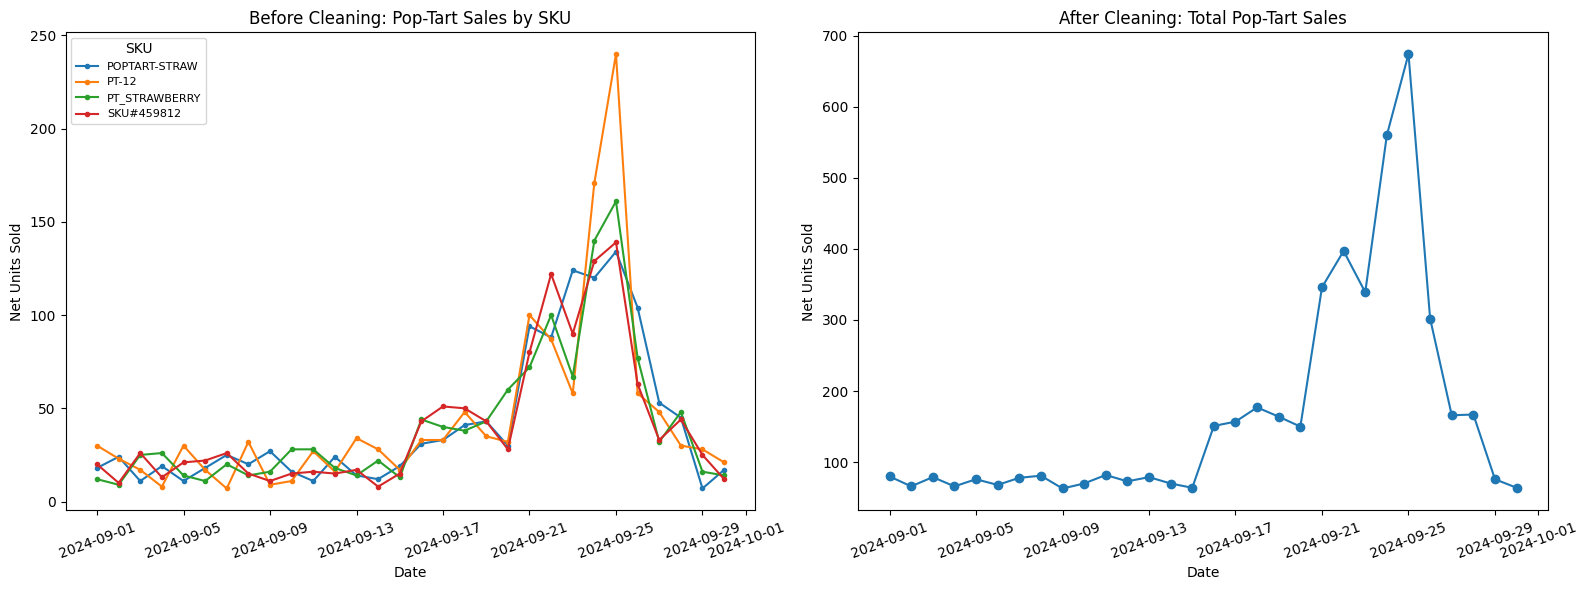

In [90]:
import matplotlib.pyplot as plt

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT: Fragmented sales by SKU
for sku, group in fragmented_daily.groupby('sku'):
    axes[0].plot(
        group['date'],
        group['quantity'],
        marker='o',
        markersize=3,
        label=sku
    )

axes[0].set_title('Before Cleaning: Pop-Tart Sales by SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Net Units Sold')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(title='SKU', fontsize=8)

# RIGHT: Consolidated daily sales
axes[1].plot(
    consolidated_daily['date'],
    consolidated_daily['total_pop_tart_units'],
    marker='o'
)

axes[1].set_title('After Cleaning: Total Pop-Tart Sales')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Net Units Sold')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [88]:
# Compare daily volume before and after consolidation

# Total volume for each SKU
sku_totals = (
    fragmented_daily
    .groupby('sku')['quantity']
    .sum()
    .sort_values(ascending=False)
)

# Daily statistics for the consolidated product
daily_summary = consolidated_daily['total_pop_tart_units'].agg(
    ['mean', 'median', 'max', 'min', 'sum']
)

print("Total units by individual SKU (fragmented view):")
display(sku_totals.to_frame(name='total_units'))

print("\nDaily statistics after consolidation:")
display(daily_summary.to_frame(name='value'))

print(
    "\nNumber of separate Pop-Tart SKUs:",
    len(sku_totals)
)

print(
    "Total units across all Pop-Tart SKUs:",
    sku_totals.sum()
)

Total units by individual SKU (fragmented view):


,total_units
sku,
PT-12,1328
POPTART-STRAW,1233
PT_STRAWBERRY,1222
SKU#459812,1202



Daily statistics after consolidation:


,value
mean,166.166667
median,80.500000
max,674.000000
min,63.000000
sum,4985.000000



Number of separate Pop-Tart SKUs: 4
Total units across all Pop-Tart SKUs: 4985


**Question** 2: The Pop-tarts Effect (SKU Consolidation)
After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

Requirements: Building an SKU mapping table, consolidating fragmented products, side-by-side visualization (before vs. after cleaning), written analysis of business impact.

Primary: Kiersten Secondary: Ciara**

The true daily sales volume is 4985 units, with an average of 166.17 units per day. The max was 674 units in one day. Before consolidation, there was 4 skus for the poptarts. There was PT-12, SKU#459812, POPTART-STRAW, and PT_STRAWBERRY. Each one had a total of 1,328, 1,233, 1,222, and 1,202.

The fragmented skus make it seem like the pop-tarts are not overly high in sales, but when combined they are. The fragmented would make it harder for the owners of walmart to know how much stock they need. If they used the fragmented skus, they might underestimate how much they need to order. Consolidation allows for all of the strawberry poptarts to be seen, which can improve inventory decisions and track patterns better.

## Question 3: Weather Correlation Analysis

Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

Requirements: Weather API integration, timestamp/timezone alignment, correlation analysis (scatter plot, heatmap, or time-series overlay), lag analysis discussion.

Primary: Ciara

Secondary: Olympia

## Question 4: Store-Level Geographic Patterns
Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

Requirements:Joining store location data with transactions, geographic grouping, comparing surge timing and magnitude across stores, bar chart or grouped comparison, outlier identification.

Primary: Olympia
Secondary: Camden

## Question 5: Signal vs. Artifact (Board game Investigation)

The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

Requirements:
Querying the SQLite database with sqlite3 + pandas, cross-referencing with the transaction CSV, SKU/category audit, evidence-based written argument, supporting visualization.

Primary: Camden (or whoever gets here first)

Secondary: Kiersten